# PCA Lab Exercise - Iris Dataset

Use the Iris dataset to create the six PCA plots required in the lab:

1. Feature Explained Variance Bar Plot
2. PCA Scree Plot
3. 2D PCA Scatter Plot
4. 3D PCA Scatter Plot
5. 2D PCA Biplot
6. 3D PCA Biplot


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
iris = load_iris()

X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print("Shape of X:", X.shape)
print("Feature names:", feature_names)
print("Target names:", target_names)


Shape of X: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape before PCA:", X_scaled.shape)


Shape before PCA: (150, 4)


In [5]:
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_ * 100

print("Shape after PCA:", X_pca.shape)
print("Explained variance (%):", explained)


Shape after PCA: (150, 4)
Explained variance (%): [72.96244541 22.85076179  3.66892189  0.51787091]


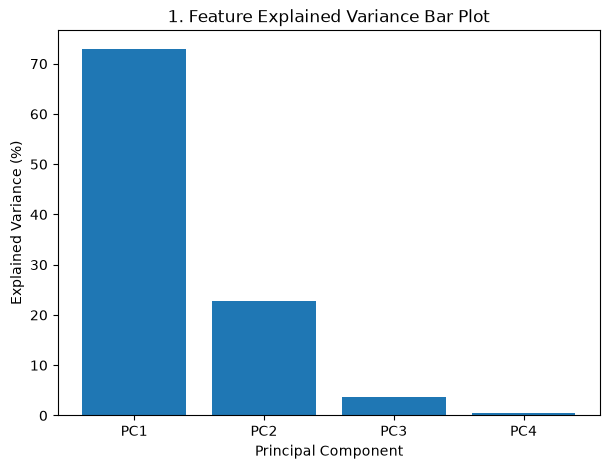

In [6]:
plt.figure(figsize=(7, 5))

plt.bar(range(1, 5), explained)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("1. Feature Explained Variance Bar Plot")
plt.xticks(range(1, 5), ["PC1", "PC2", "PC3", "PC4"])

plt.show()


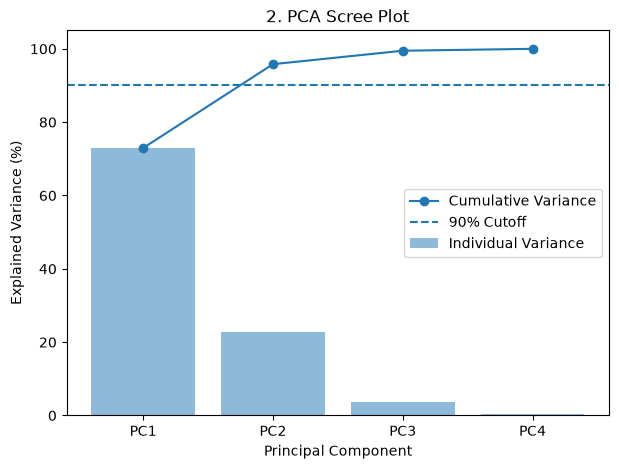

In [7]:
cumulative = np.cumsum(explained)

plt.figure(figsize=(7, 5))

plt.bar(range(1, 5), explained, alpha=0.5, label="Individual Variance")
plt.plot(range(1, 5), cumulative, marker="o", label="Cumulative Variance")
plt.axhline(90, linestyle="--", label="90% Cutoff")

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("2. PCA Scree Plot")
plt.xticks(range(1, 5), ["PC1", "PC2", "PC3", "PC4"])
plt.legend()

plt.show()


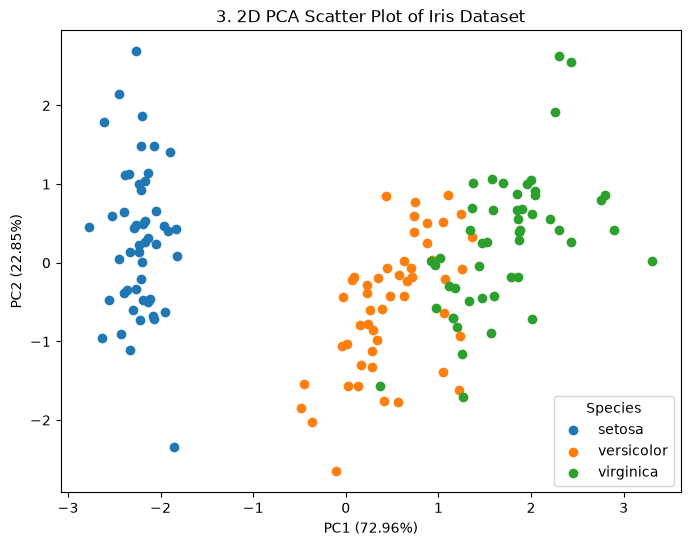

In [8]:
plt.figure(figsize=(8, 6))

for i, name in enumerate(target_names):
    points = y == i
    plt.scatter(X_pca[points, 0], X_pca[points, 1], label=name)

plt.xlabel(f"PC1 ({explained[0]:.2f}%)")
plt.ylabel(f"PC2 ({explained[1]:.2f}%)")
plt.title("3. 2D PCA Scatter Plot of Iris Dataset")
plt.legend(title="Species")

plt.show()


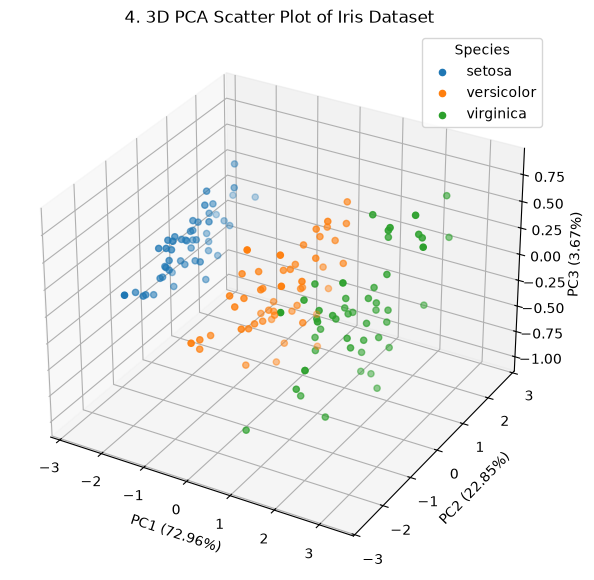

In [9]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for i, name in enumerate(target_names):
    points = y == i
    ax.scatter(
        X_pca[points, 0],
        X_pca[points, 1],
        X_pca[points, 2],
        label=name
    )

ax.set_xlabel(f"PC1 ({explained[0]:.2f}%)")
ax.set_ylabel(f"PC2 ({explained[1]:.2f}%)")
ax.set_zlabel(f"PC3 ({explained[2]:.2f}%)")
ax.set_title("4. 3D PCA Scatter Plot of Iris Dataset")
ax.legend(title="Species")

plt.show()


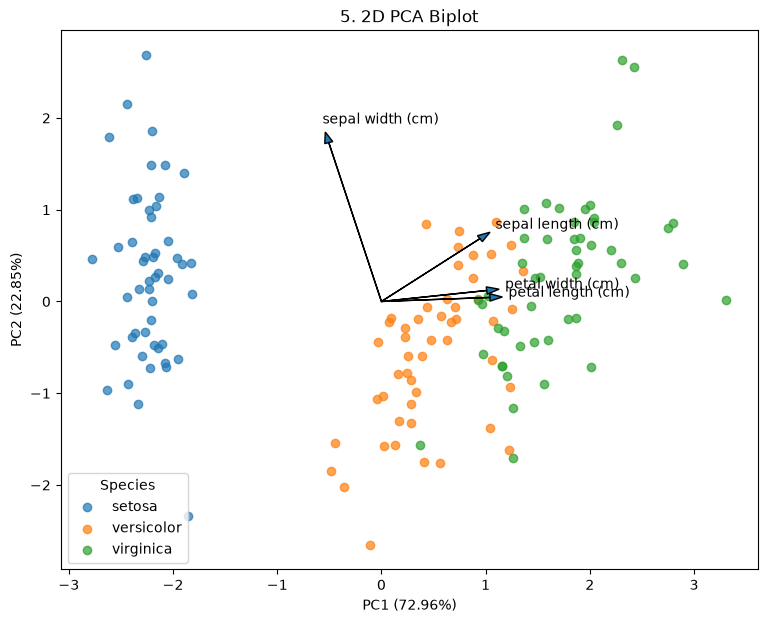

In [10]:
plt.figure(figsize=(9, 7))

for i, name in enumerate(target_names):
    points = y == i
    plt.scatter(X_pca[points, 0], X_pca[points, 1], label=name, alpha=0.7)

for i, feature in enumerate(feature_names):
    x = pca.components_[0, i]
    y_arrow = pca.components_[1, i]

    plt.arrow(
        0, 0,
        x * 2,
        y_arrow * 2,
        head_width=0.08,
        length_includes_head=True
    )

    plt.text(x * 2.1, y_arrow * 2.1, feature)

plt.xlabel(f"PC1 ({explained[0]:.2f}%)")
plt.ylabel(f"PC2 ({explained[1]:.2f}%)")
plt.title("5. 2D PCA Biplot")
plt.legend(title="Species")

plt.show()


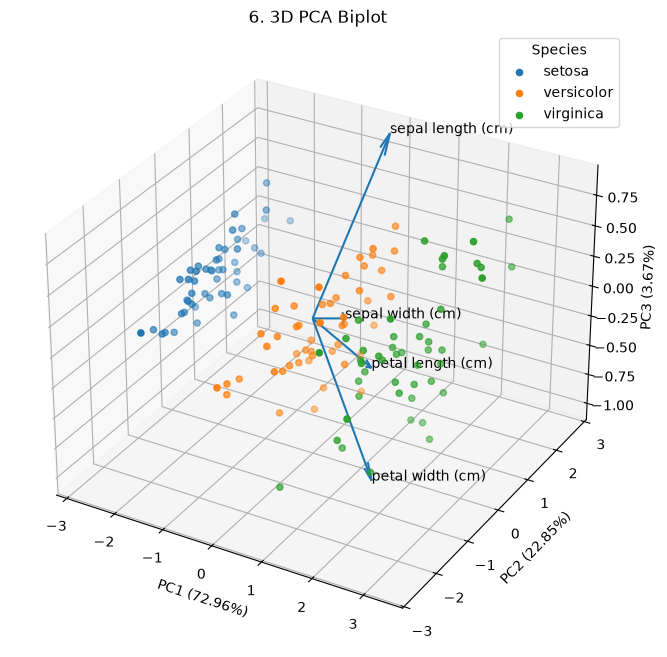

In [11]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for i, name in enumerate(target_names):
    points = y == i
    ax.scatter(
        X_pca[points, 0],
        X_pca[points, 1],
        X_pca[points, 2],
        label=name
    )

for i, feature in enumerate(feature_names):
    x = pca.components_[0, i] * 2
    y_arrow = pca.components_[1, i] * 2
    z = pca.components_[2, i] * 2

    ax.quiver(
        0, 0, 0,
        x, y_arrow, z,
        arrow_length_ratio=0.1
    )

    ax.text(x, y_arrow, z, feature)

ax.set_xlabel(f"PC1 ({explained[0]:.2f}%)")
ax.set_ylabel(f"PC2 ({explained[1]:.2f}%)")
ax.set_zlabel(f"PC3 ({explained[2]:.2f}%)")
ax.set_title("6. 3D PCA Biplot")
ax.legend(title="Species")

plt.show()
